In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn scipy

In [3]:
# Import all the tools we'll use
import pandas as pd  # For working with data tables
import numpy as np  # For math operations
import matplotlib.pyplot as plt  # For making graphs
import seaborn as sns  # For making pretty graphs

# For preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# For clustering
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture

# For evaluation
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Make graphs look nice
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [4]:
# Download the dataset from UCI repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
df = pd.read_csv(url)

# Show the first few rows to see what it looks like
print("First 5 rows of data:")
print(df.head())

First 5 rows of data:
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


In [9]:
# Get detailed information
print("="*50)
print("DATASET INFORMATION")
print("="*50)

print(f"\n1. Shape of dataset: {df.shape}")
print(f"   - Number of customers (rows): {df.shape[0]}")
print(f"   - Number of features (columns): {df.shape[1]}")

print("\n2. Column names:")
print(f"   {df.columns.tolist()}")

print("\n3. Data types of each column:")
print(df.dtypes)

print("\n4. Memory usage:")
print(f"   {df.memory_usage(deep=True).sum() / 1024:.2f} KB")



DATASET INFORMATION

1. Shape of dataset: (440, 8)
   - Number of customers (rows): 440
   - Number of features (columns): 8

2. Column names:
   ['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

3. Data types of each column:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

4. Memory usage:
   27.63 KB


In [10]:
# Get statistical summary
print("STATISTICAL SUMMARY")
print("="*70)
df.describe()

STATISTICAL SUMMARY


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [11]:
# Check for missing values
print("MISSING VALUES CHECK")
print("="*50)

# Count missing values in each column
missing_counts = df.isnull().sum()
print("\nMissing values per column:")
print(missing_counts)

# Calculate percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("\nPercentage of missing values:")
print(missing_percentage)

# Total missing values
total_missing = df.isnull().sum().sum()
print(f"\n📊 Total missing values in entire dataset: {total_missing}")

if total_missing == 0:
    print("✅ Great! No missing values found!")
else:
    print(f"⚠️ Warning: {total_missing} missing values found!")

MISSING VALUES CHECK

Missing values per column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Percentage of missing values:
Channel             0.0
Region              0.0
Fresh               0.0
Milk                0.0
Grocery             0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen          0.0
dtype: float64

📊 Total missing values in entire dataset: 0
✅ Great! No missing values found!


In [12]:
# Check for duplicate rows
print("DUPLICATE ROWS CHECK")
print("="*50)

# Count duplicates
num_duplicates = df.duplicated().sum()
print(f"\n📊 Number of duplicate rows: {num_duplicates}")

# Show shape before
print(f"\nDataset shape BEFORE removing duplicates: {df.shape}")

# Remove duplicates
df = df.drop_duplicates()

# Show shape after
print(f"Dataset shape AFTER removing duplicates: {df.shape}")

if num_duplicates == 0:
    print("\n✅ No duplicates found!")
else:
    print(f"\n✅ Removed {num_duplicates} duplicate rows!")


DUPLICATE ROWS CHECK

📊 Number of duplicate rows: 0

Dataset shape BEFORE removing duplicates: (440, 8)
Dataset shape AFTER removing duplicates: (440, 8)

✅ No duplicates found!


In [13]:
# Select which columns to use for clustering
print("FEATURE SELECTION FOR CLUSTERING")
print("="*50)

# We will NOT use Channel and Region because:
# - They are categorical (categories, not amounts)
# - Channel: 1 or 2 (just labels, not meaningful numbers)
# - Region: 1, 2, or 3 (just labels)

# We WILL use these 6 features (all are spending amounts):
features_to_cluster = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

# Create a new dataset with only these features
X = df[features_to_cluster].copy()

print(f"\n✅ Selected {len(features_to_cluster)} features for clustering:")
for i, feature in enumerate(features_to_cluster, 1):
    print(f"   {i}. {feature}")

print(f"\n📊 Shape of clustering dataset: {X.shape}")
print(f"   - {X.shape[0]} customers")
print(f"   - {X.shape[1]} features per customer")

FEATURE SELECTION FOR CLUSTERING

✅ Selected 6 features for clustering:
   1. Fresh
   2. Milk
   3. Grocery
   4. Frozen
   5. Detergents_Paper
   6. Delicassen

📊 Shape of clustering dataset: (440, 6)
   - 440 customers
   - 6 features per customer


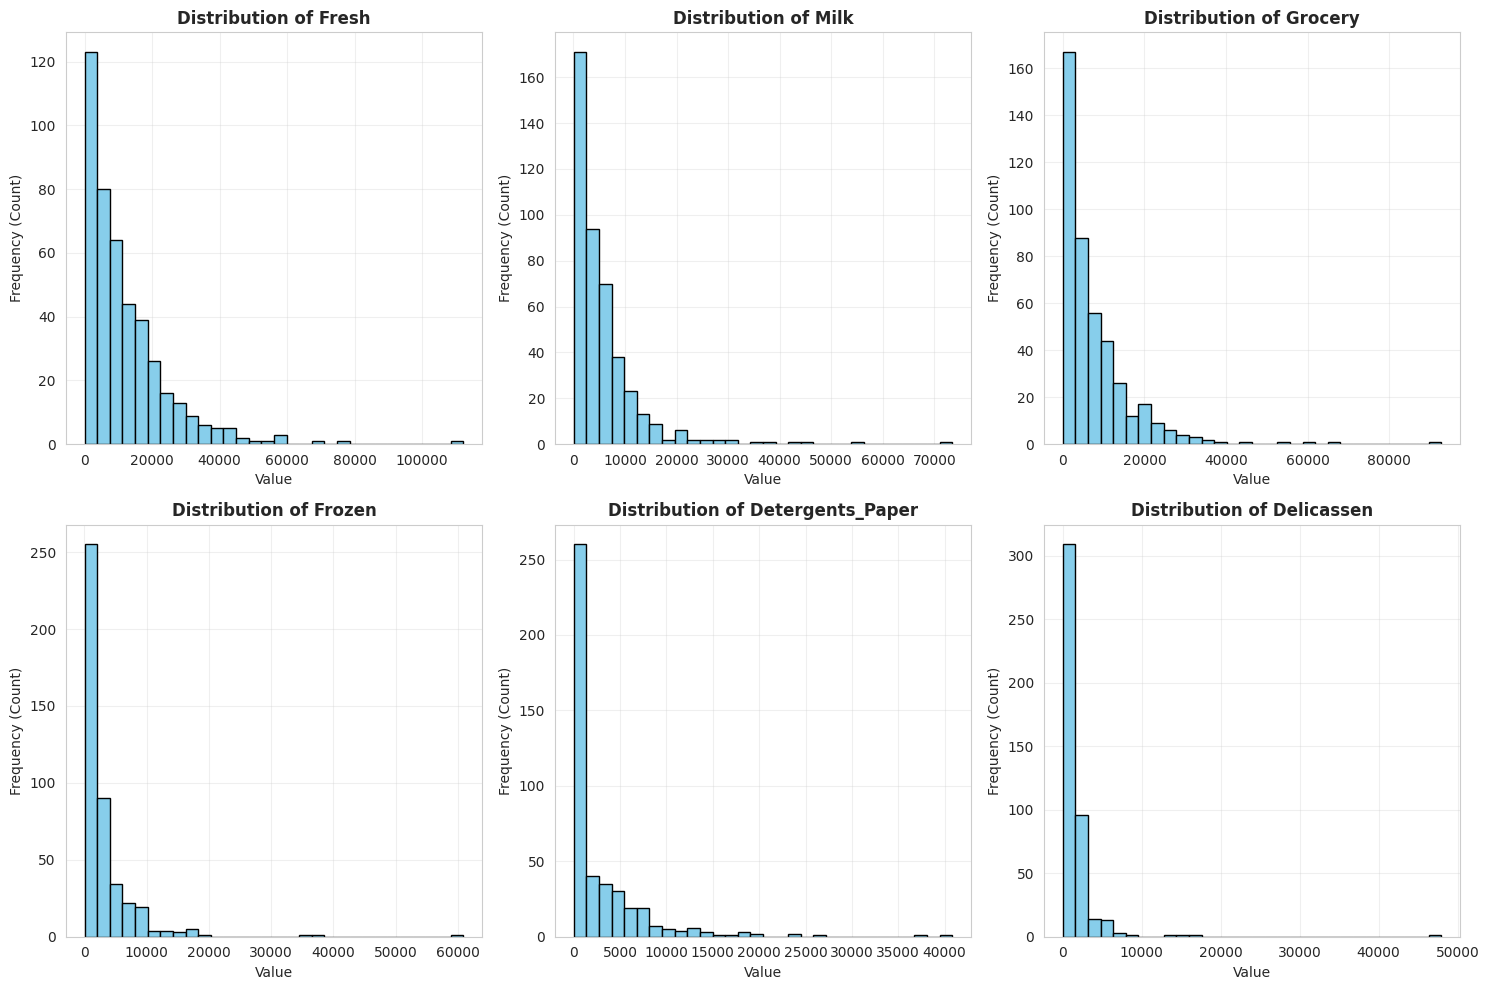

✅ Distribution plots created!


In [14]:
# Import the plotting library
import matplotlib.pyplot as plt

# Set the size of our figure
plt.figure(figsize=(15, 10))

# Create 6 small plots (2 rows, 3 columns)
for i, column in enumerate(features_to_cluster, 1):
    plt.subplot(2, 3, i)  # Position: row, column, plot number
    plt.hist(X[column], bins=30, color='skyblue', edgecolor='black')
    plt.title(f'Distribution of {column}', fontsize=12, fontweight='bold')
    plt.xlabel('Value')
    plt.ylabel('Frequency (Count)')
    plt.grid(True, alpha=0.3)

# Adjust spacing between plots
plt.tight_layout()
plt.show()

print("✅ Distribution plots created!")

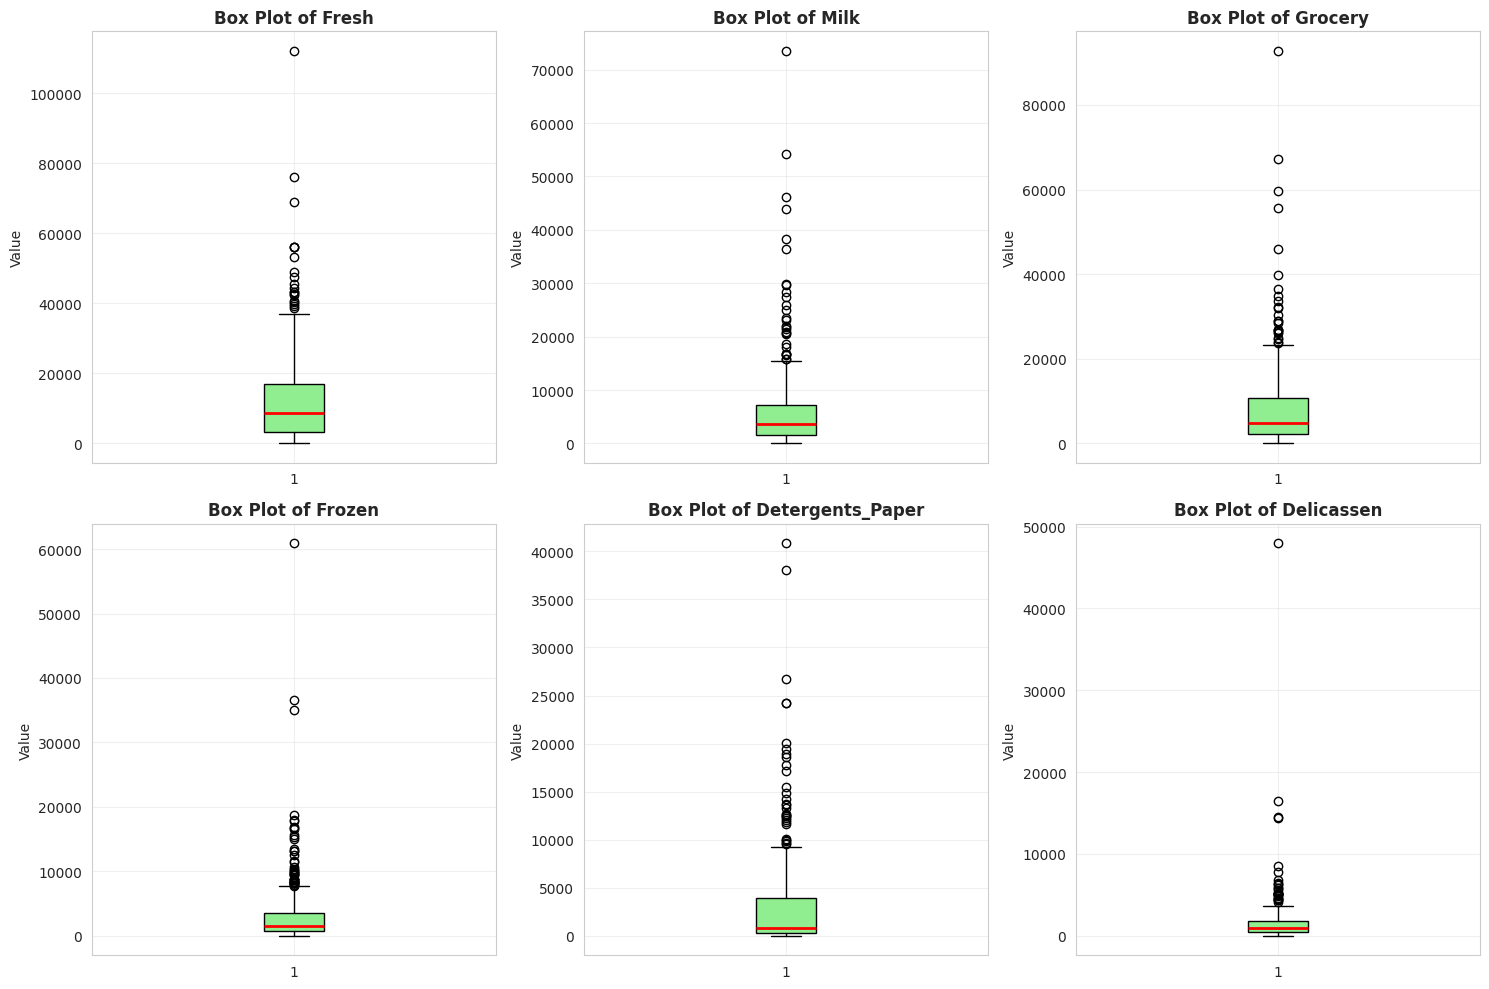

✅ Box plots created!


In [15]:
# Create box plots to visualize outliers
plt.figure(figsize=(15, 10))

for i, column in enumerate(features_to_cluster, 1):
    plt.subplot(2, 3, i)

    # Create box plot
    plt.boxplot(X[column], vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightgreen', color='black'),
                whiskerprops=dict(color='black'),
                capprops=dict(color='black'),
                medianprops=dict(color='red', linewidth=2))

    plt.title(f'Box Plot of {column}', fontsize=12, fontweight='bold')
    plt.ylabel('Value')
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Box plots created!")

In [20]:
from scipy import stats

# Calculate Z-scores for all values
# Z-score = (value - mean) / standard_deviation
# Z-score tells you how many standard deviations away from average
z_scores = np.abs(stats.zscore(X))

# Count outliers (Z-score > 3 means very unusual)
outliers_per_feature = (z_scores > 3).sum(axis=0)

print("OUTLIER DETECTION (Z-Score Method)")
print("="*60)
print("\nA Z-score > 3 means the value is very far from average")
print("(more than 3 standard deviations away)\n")

for feature, count in zip(features_to_cluster, outliers_per_feature):
    percentage = (count / len(X)) * 100
    print(f"{feature:20} : {count:3} outliers ({percentage:5.2f}%)")

total_outliers = outliers_per_feature.sum()
print(f"\n{'TOTAL':20} : {total_outliers:3} outlier values")
print(f"\nNote: Same customer can be an outlier in multiple features")

OUTLIER DETECTION (Z-Score Method)

A Z-score > 3 means the value is very far from average
(more than 3 standard deviations away)

Fresh                :   7 outliers ( 1.59%)
Milk                 :   9 outliers ( 2.05%)
Grocery              :   7 outliers ( 1.59%)
Frozen               :   6 outliers ( 1.36%)
Detergents_Paper     :  10 outliers ( 2.27%)
Delicassen           :   4 outliers ( 0.91%)

TOTAL                :  43 outlier values

Note: Same customer can be an outlier in multiple features


In [21]:
# IMPORTANT: Save the original data before scaling
# We'll need this later for cluster profiling
X_original = X.copy()

print("FEATURE SCALING")
print("="*60)
print("\nWhy do we need scaling?")
print("- Different features have different ranges")
print("- Fresh: 3 to 112,151")
print("- Frozen: 25 to 60,869")
print("- Clustering algorithms use distance")
print("- Large values dominate the distance calculation")
print("- Scaling makes all features equally important")
print("\n" + "="*60)

FEATURE SCALING

Why do we need scaling?
- Different features have different ranges
- Fresh: 3 to 112,151
- Frozen: 25 to 60,869
- Clustering algorithms use distance
- Large values dominate the distance calculation
- Scaling makes all features equally important



In [22]:
# Import the scaling tool
from sklearn.preprocessing import StandardScaler

# Create a scaler object
scaler = StandardScaler()

# Fit the scaler and transform the data
# "Fit" = calculate mean and std for each feature
# "Transform" = apply the formula: (value - mean) / std
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame (makes it easier to work with)
X_scaled = pd.DataFrame(X_scaled, columns=features_to_cluster)

print("✅ Standardization applied!")
print("\nAfter standardization:")
print("- Each feature has mean ≈ 0")
print("- Each feature has standard deviation ≈ 1")
print("\nLet's verify this:\n")

# Show statistics after scaling
print("Statistics AFTER scaling:")
print(X_scaled.describe())

✅ Standardization applied!

After standardization:
- Each feature has mean ≈ 0
- Each feature has standard deviation ≈ 1

Let's verify this:

Statistics AFTER scaling:
              Fresh        Milk       Grocery        Frozen  Detergents_Paper  \
count  4.400000e+02  440.000000  4.400000e+02  4.400000e+02      4.400000e+02   
mean  -3.431598e-17    0.000000 -4.037175e-17  3.633457e-17      2.422305e-17   
std    1.001138e+00    1.001138  1.001138e+00  1.001138e+00      1.001138e+00   
min   -9.496831e-01   -0.778795 -8.373344e-01 -6.283430e-01     -6.044165e-01   
25%   -7.023339e-01   -0.578306 -6.108364e-01 -4.804306e-01     -5.511349e-01   
50%   -2.767602e-01   -0.294258 -3.366684e-01 -3.188045e-01     -4.336004e-01   
75%    3.905226e-01    0.189092  2.849105e-01  9.946441e-02      2.184822e-01   
max    7.927738e+00    9.183650  8.936528e+00  1.191900e+01      7.967672e+00   

         Delicassen  
count  4.400000e+02  
mean  -8.074349e-18  
std    1.001138e+00  
min   -5.40264

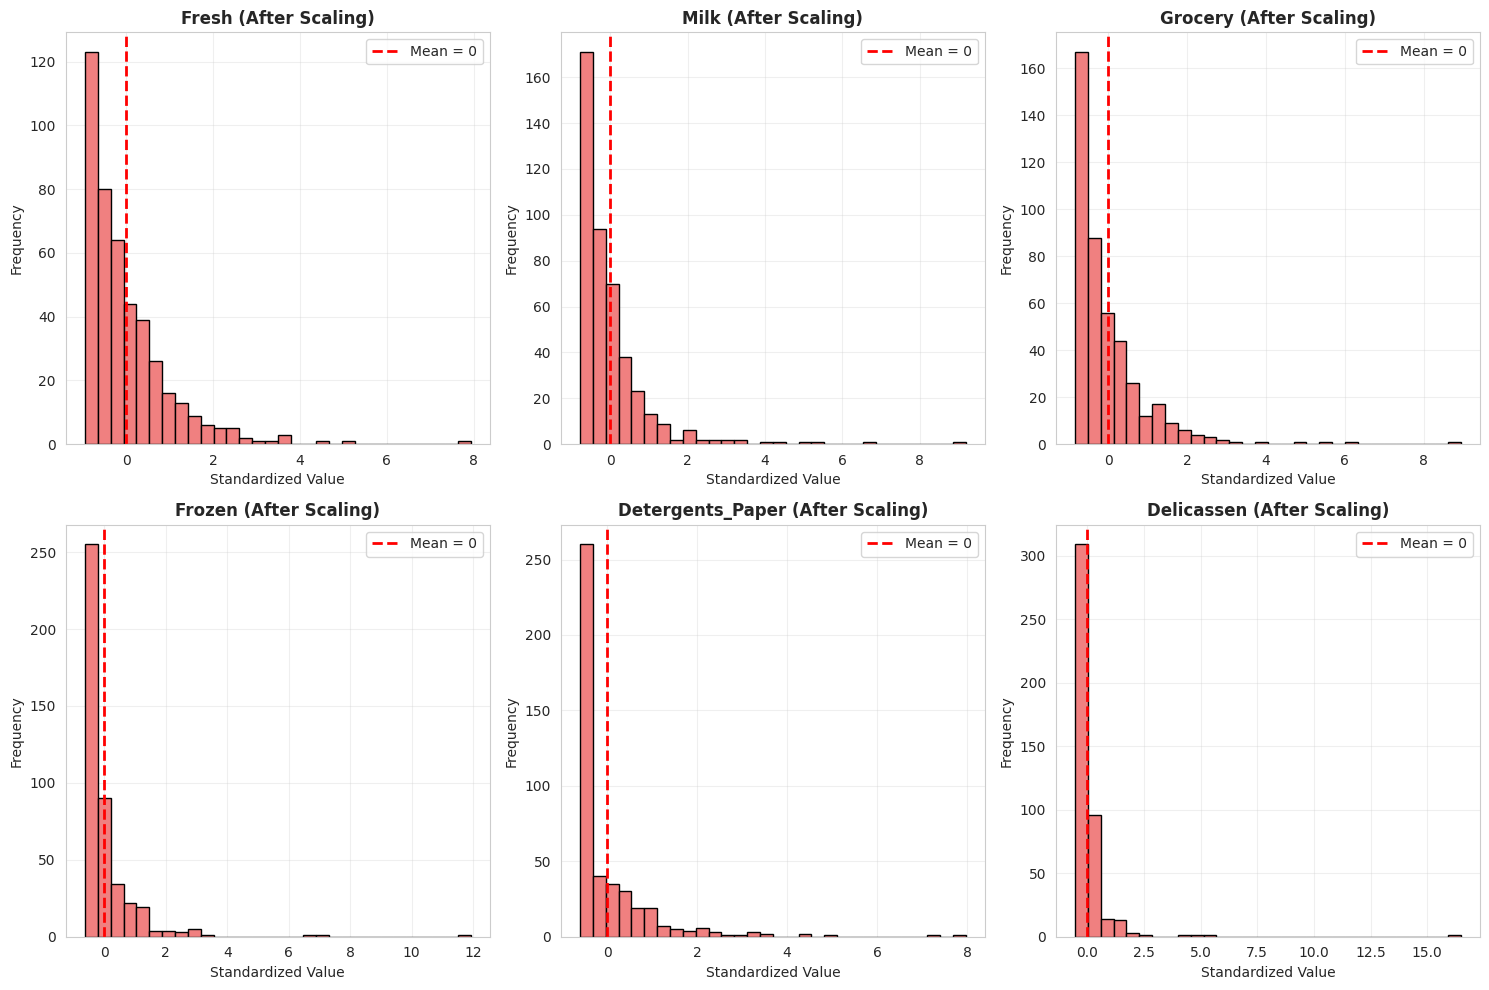

✅ Scaled distribution plots created!

Notice: All features now centered around 0


In [23]:
# Compare distributions before and after scaling
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()  # Flatten to make it easier to loop through

for i, column in enumerate(features_to_cluster):
    axes[i].hist(X_scaled[column], bins=30, color='lightcoral', edgecolor='black')
    axes[i].axvline(x=0, color='red', linestyle='--', linewidth=2, label='Mean = 0')
    axes[i].set_title(f'{column} (After Scaling)', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Standardized Value')
    axes[i].set_ylabel('Frequency')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Scaled distribution plots created!")
print("\nNotice: All features now centered around 0")

CORRELATION ANALYSIS

Correlation tells us if features move together:
  +1.0 = Perfect positive correlation (both increase together)
   0.0 = No correlation (independent)
  -1.0 = Perfect negative correlation (one increases, other decreases)




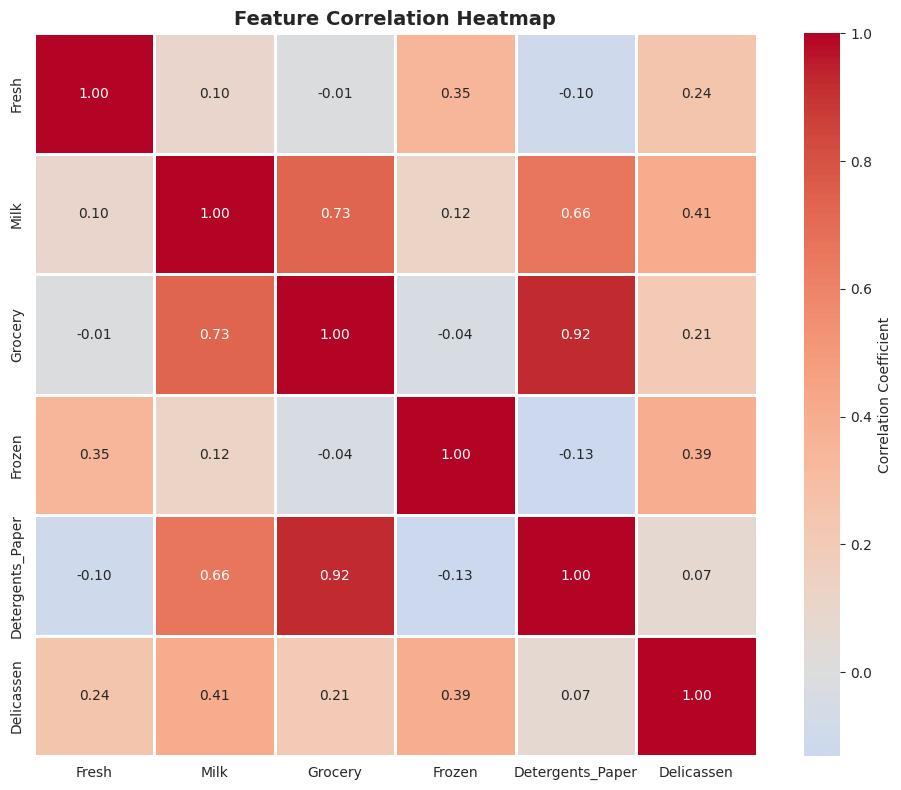


✅ Correlation heatmap created!


In [24]:
# Calculate correlation between all pairs of features
correlation_matrix = X_scaled.corr()

print("CORRELATION ANALYSIS")
print("="*60)
print("\nCorrelation tells us if features move together:")
print("  +1.0 = Perfect positive correlation (both increase together)")
print("   0.0 = No correlation (independent)")
print("  -1.0 = Perfect negative correlation (one increases, other decreases)")
print("\n" + "="*60 + "\n")

# Create heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,
            annot=True,           # Show numbers in cells
            fmt='.2f',            # Format: 2 decimal places
            cmap='coolwarm',      # Color scheme: blue=negative, red=positive
            center=0,             # Center color at 0
            square=True,          # Make cells square
            linewidths=1,         # Lines between cells
            cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✅ Correlation heatmap created!")

Creating pairwise scatter plots...

What this shows:
- Each small plot compares two features
- Diagonal shows distribution of single feature
- Off-diagonal shows relationship between two features




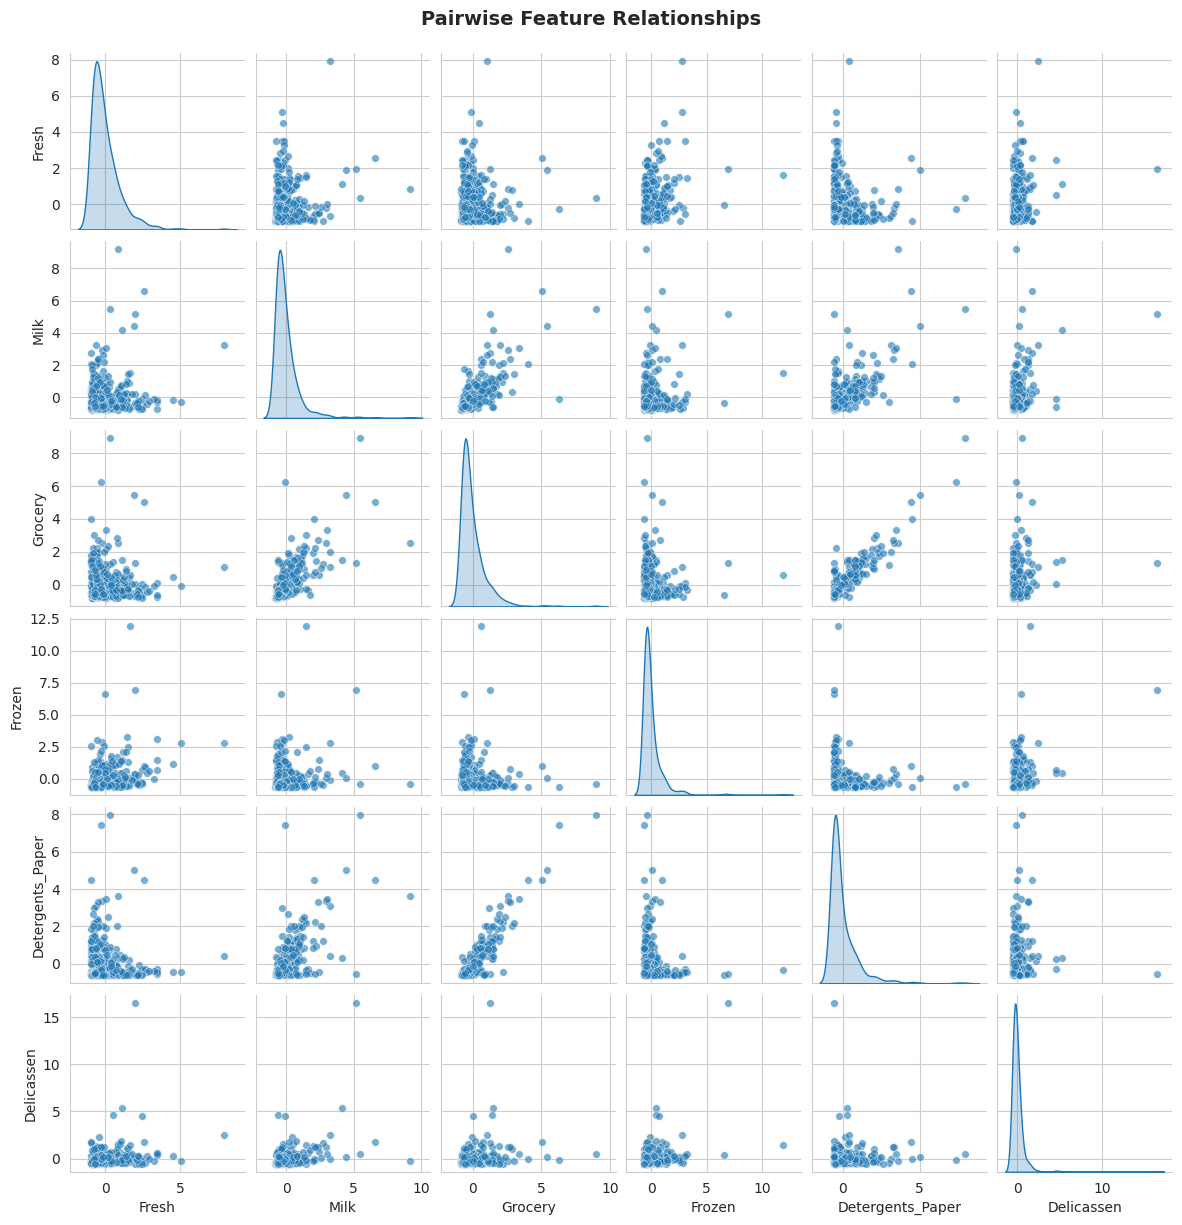

✅ Pairplot created!


In [26]:
print("Creating pairwise scatter plots...")
print("\nWhat this shows:")
print("- Each small plot compares two features")
print("- Diagonal shows distribution of single feature")
print("- Off-diagonal shows relationship between two features")
print("\n" + "="*60 + "\n")

# Create pairplot
pairplot = sns.pairplot(X_scaled,
                        diag_kind='kde',     # Diagonal: density curve
                        plot_kws={'alpha': 0.6, 's': 30},  # Transparency and dot size
                        height=2)            # Size of each subplot

pairplot.fig.suptitle('Pairwise Feature Relationships', y=1.02, fontsize=14, fontweight='bold')
plt.show()

print("✅ Pairplot created!")

In [27]:
# Import PCA
from sklearn.decomposition import PCA

print("PRINCIPAL COMPONENT ANALYSIS (PCA)")
print("="*60)
print("\nWhat is PCA?")
print("- We have 6 features (6 dimensions)")
print("- Hard to visualize 6 dimensions!")
print("- PCA finds the 2 most important directions")
print("- Projects data onto these 2 directions")
print("- Now we can plot it in 2D!")
print("\n" + "="*60 + "\n")

# Create PCA with 2 components
pca = PCA(n_components=2)

# Fit and transform the data
X_pca = pca.fit_transform(X_scaled)

# Show how much information we kept
print("Variance explained by each component:")
print(f"  PC1: {pca.explained_variance_ratio_[0]:.2%}")
print(f"  PC2: {pca.explained_variance_ratio_[1]:.2%}")
print(f"  Total: {pca.explained_variance_ratio_.sum():.2%}")

print("\nWhat this means:")
if pca.explained_variance_ratio_.sum() > 0.7:
    print("✅ Good! We kept >70% of the information in 2D")
else:
    print("⚠️ We lost some information, but that's okay for visualization")

print(f"\nShape after PCA: {X_pca.shape}")
print(f"  - {X_pca.shape[0]} customers")
print(f"  - {X_pca.shape[1]} dimensions (reduced from 6!)")

PRINCIPAL COMPONENT ANALYSIS (PCA)

What is PCA?
- We have 6 features (6 dimensions)
- Hard to visualize 6 dimensions!
- PCA finds the 2 most important directions
- Projects data onto these 2 directions
- Now we can plot it in 2D!


Variance explained by each component:
  PC1: 44.08%
  PC2: 28.38%
  Total: 72.46%

What this means:
✅ Good! We kept >70% of the information in 2D

Shape after PCA: (440, 2)
  - 440 customers
  - 2 dimensions (reduced from 6!)


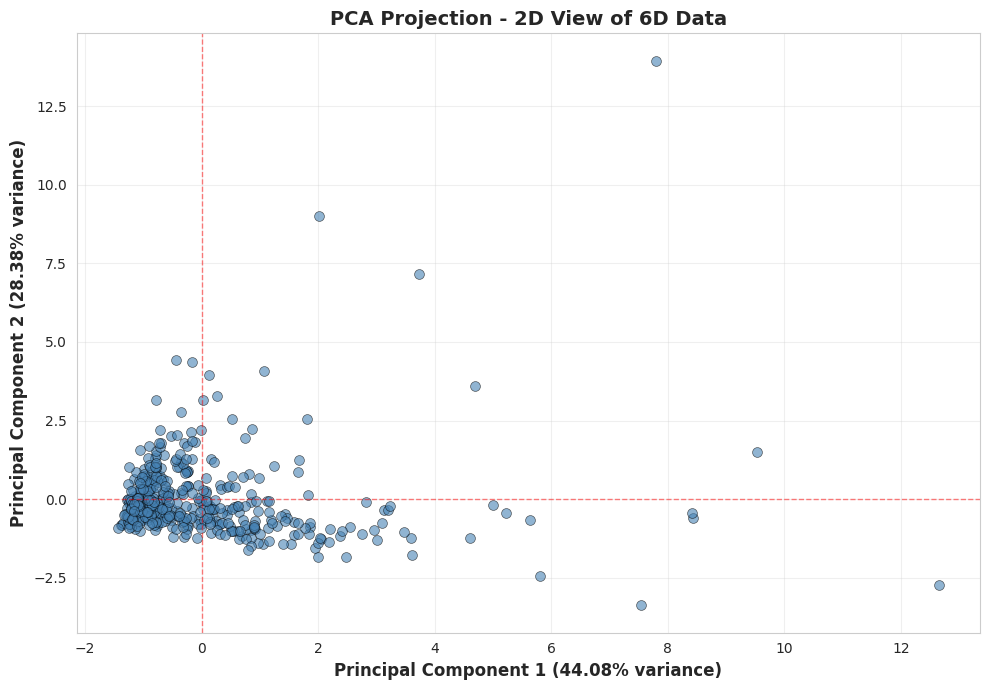

✅ PCA visualization created!

What to look for:
  - Clusters of points = groups of similar customers
  - Spread = diversity in customer behavior
  - Outliers = unusual customers


In [28]:
# Create scatter plot of PCA projection
plt.figure(figsize=(10, 7))

plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c='steelblue',      # Color
            alpha=0.6,          # Transparency
            s=50,               # Size
            edgecolors='black', # Border around dots
            linewidth=0.5)      # Border thickness

plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.2%} variance)',
           fontsize=12, fontweight='bold')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.2%} variance)',
           fontsize=12, fontweight='bold')
plt.title('PCA Projection - 2D View of 6D Data', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)
plt.axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

print("✅ PCA visualization created!")
print("\nWhat to look for:")
print("  - Clusters of points = groups of similar customers")
print("  - Spread = diversity in customer behavior")
print("  - Outliers = unusual customers")

In [29]:
# Import t-SNE
from sklearn.manifold import TSNE

print("t-SNE (t-Distributed Stochastic Neighbor Embedding)")
print("="*60)
print("\nWhat is t-SNE?")
print("- Another way to visualize 6D data in 2D")
print("- Better at preserving local structure (nearby points stay nearby)")
print("- Often reveals clusters more clearly than PCA")
print("- Slower than PCA (may take 30 seconds)")
print("\nStarting t-SNE computation...")
print("Please wait...")

# Create t-SNE with 2 components
tsne = TSNE(n_components=2,      # Reduce to 2D
            random_state=42,      # For reproducibility
            perplexity=30,        # Balance local vs global structure
            n_iter=1000)          # Number of iterations

# Fit and transform
X_tsne = tsne.fit_transform(X_scaled)

print("\n✅ t-SNE computation complete!")
print(f"Shape after t-SNE: {X_tsne.shape}")

t-SNE (t-Distributed Stochastic Neighbor Embedding)

What is t-SNE?
- Another way to visualize 6D data in 2D
- Better at preserving local structure (nearby points stay nearby)
- Often reveals clusters more clearly than PCA
- Slower than PCA (may take 30 seconds)

Starting t-SNE computation...
Please wait...

✅ t-SNE computation complete!
Shape after t-SNE: (440, 2)


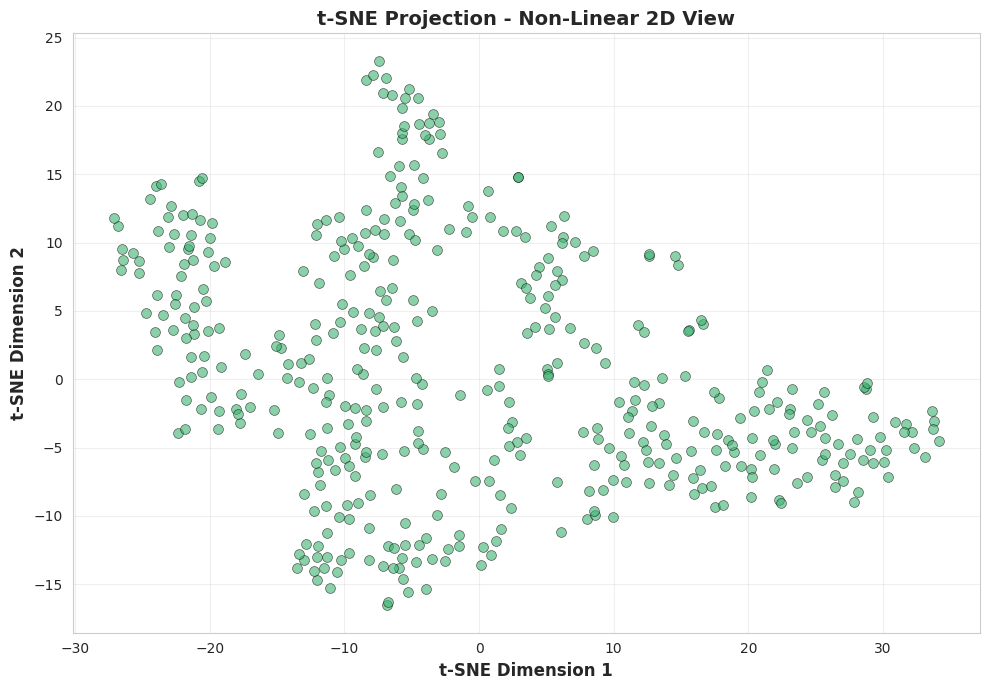

✅ t-SNE visualization created!

Compare this with PCA:
  - t-SNE often separates clusters more clearly
  - But distances between clusters are less meaningful in t-SNE


In [31]:
# Create scatter plot of t-SNE projection
plt.figure(figsize=(10, 7))

plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
            c='mediumseagreen',  # Color
            alpha=0.6,           # Transparency
            s=50,                # Size
            edgecolors='black',  # Border
            linewidth=0.5)       # Border thickness

plt.xlabel('t-SNE Dimension 1', fontsize=12, fontweight='bold')
plt.ylabel('t-SNE Dimension 2', fontsize=12, fontweight='bold')
plt.title('t-SNE Projection - Non-Linear 2D View', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ t-SNE visualization created!")
print("\nCompare this with PCA:")
print("  - t-SNE often separates clusters more clearly")
print("  - But distances between clusters are less meaningful in t-SNE")

In [33]:
# Import clustering and evaluation libraries

from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    silhouette_samples
)
from scipy.spatial.distance import cdist, pdist, squareform

print("✅ Clustering and evaluation libraries imported successfully!")

✅ Clustering and evaluation libraries imported successfully!


In [34]:
# Apply Elbow Method to find a suitable number of clusters for K-Means

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

print("✅ Inertia values calculated for K = 1 to 10")
print("Inertia values:", inertia_values)

✅ Inertia values calculated for K = 1 to 10
Inertia values: [2639.9999999999977, 1956.1242775222677, 1608.4311488289443, 1317.8383605390695, 1058.77125325701, 915.7412597498413, 825.4002520218324, 737.3862033362676, 661.4495846389705, 605.9151092090291]


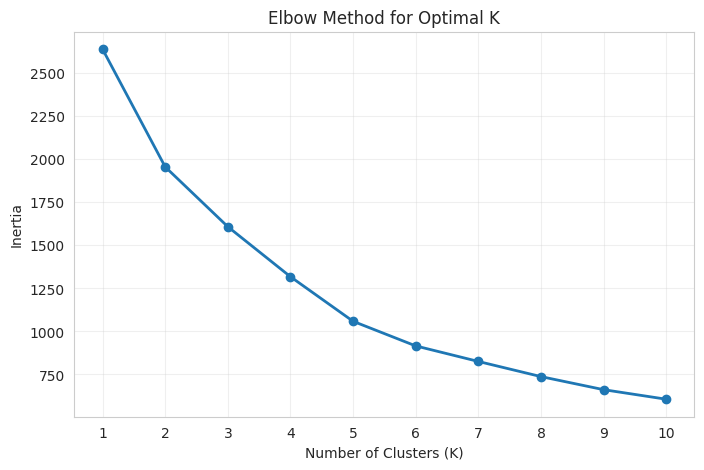

✅ Elbow curve plotted.
Observation: Look for the point where the drop in inertia starts slowing down.


In [35]:
# Visualize the Elbow curve

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o', linewidth=2)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.show()

print("✅ Elbow curve plotted.")
print("Observation: Look for the point where the drop in inertia starts slowing down.")

In [36]:
#  Define Dunn Index function manually becuse it is not predefined
# Dunn Index = minimum inter-cluster distance / maximum intra-cluster diameter
# Higher Dunn Index is better

def dunn_index(X, labels):
    unique_clusters = np.unique(labels)

    # Calculate intra-cluster distances (cluster diameters)
    intra_cluster_distances = []
    for cluster in unique_clusters:
        cluster_points = X[labels == cluster]
        if len(cluster_points) > 1:
            distances = pdist(cluster_points)
            intra_cluster_distances.append(np.max(distances))
        else:
            intra_cluster_distances.append(0)

    max_intra = np.max(intra_cluster_distances)

    # Calculate inter-cluster distances
    inter_cluster_distances = []
    for i, cluster_i in enumerate(unique_clusters):
        for j, cluster_j in enumerate(unique_clusters):
            if i < j:
                points_i = X[labels == cluster_i]
                points_j = X[labels == cluster_j]
                distances = cdist(points_i, points_j)
                inter_cluster_distances.append(np.min(distances))

    min_inter = np.min(inter_cluster_distances)

    # Avoid division by zero
    if max_intra == 0:
        return 0

    return min_inter / max_intra

print("✅ Dunn Index function defined.")

✅ Dunn Index function defined.


In [37]:
#  Gap Statistic (Extra Evaluation Technique)

import numpy as np
from sklearn.cluster import KMeans

def compute_gap_statistic(X, k, n_refs=5):
    """
    Computes the Gap Statistic for a given k.
    Higher Gap value = better clustering
    """
    # Fit original data
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    original_inertia = kmeans.inertia_

    # Generate reference datasets
    ref_inertia = []

    for _ in range(n_refs):
        random_data = np.random.uniform(
            low=X.min().min(),
            high=X.max().max(),
            size=X.shape
        )

        kmeans_ref = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans_ref.fit(random_data)
        ref_inertia.append(kmeans_ref.inertia_)

    # Compute Gap
    gap = np.log(np.mean(ref_inertia)) - np.log(original_inertia)

    return gap

print("✅ Gap Statistic function defined.")

✅ Gap Statistic function defined.


In [38]:
#  Apply K-Means for K = 2, 3, 4

kmeans_results = {}
kmeans_labels_dict = {}

for k in [2, 3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    kmeans_results[k] = kmeans
    kmeans_labels_dict[k] = labels

    print(f"✅ K-Means completed for K = {k}")

✅ K-Means completed for K = 2
✅ K-Means completed for K = 3
✅ K-Means completed for K = 4


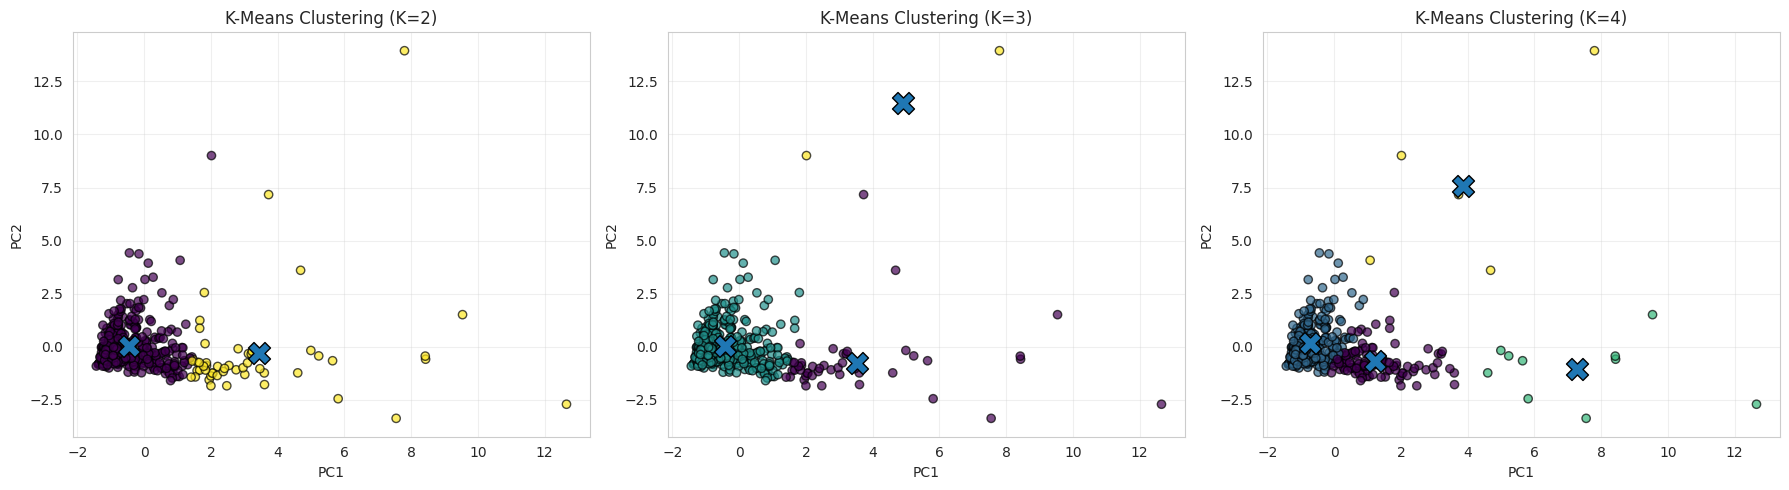

✅ K-Means cluster visualizations created for K = 2, 3, 4.


In [39]:
# Visualize K-Means clustering results using PCA projection

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, k in enumerate([2, 3, 4]):
    labels = kmeans_labels_dict[k]
    model = kmeans_results[k]

    axes[idx].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', alpha=0.7, edgecolor='black')

    # Project cluster centers into PCA space
    centers_pca = pca.transform(model.cluster_centers_)
    axes[idx].scatter(centers_pca[:, 0], centers_pca[:, 1], marker='X', s=250, edgecolor='black')

    axes[idx].set_title(f'K-Means Clustering (K={k})')
    axes[idx].set_xlabel('PC1')
    axes[idx].set_ylabel('PC2')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ K-Means cluster visualizations created for K = 2, 3, 4.")

In [41]:
#  Apply Spectral Clustering for K = 2, 3, 4

spectral_labels_dict = {}

for k in [2, 3, 4]:
    spectral = SpectralClustering(
        n_clusters=k,
        affinity='nearest_neighbors',
        random_state=42,
        assign_labels='kmeans'
    )

    labels = spectral.fit_predict(X_scaled)
    spectral_labels_dict[k] = labels

    print(f"✅ Spectral Clustering completed for K = {k}")

✅ Spectral Clustering completed for K = 2
✅ Spectral Clustering completed for K = 3
✅ Spectral Clustering completed for K = 4


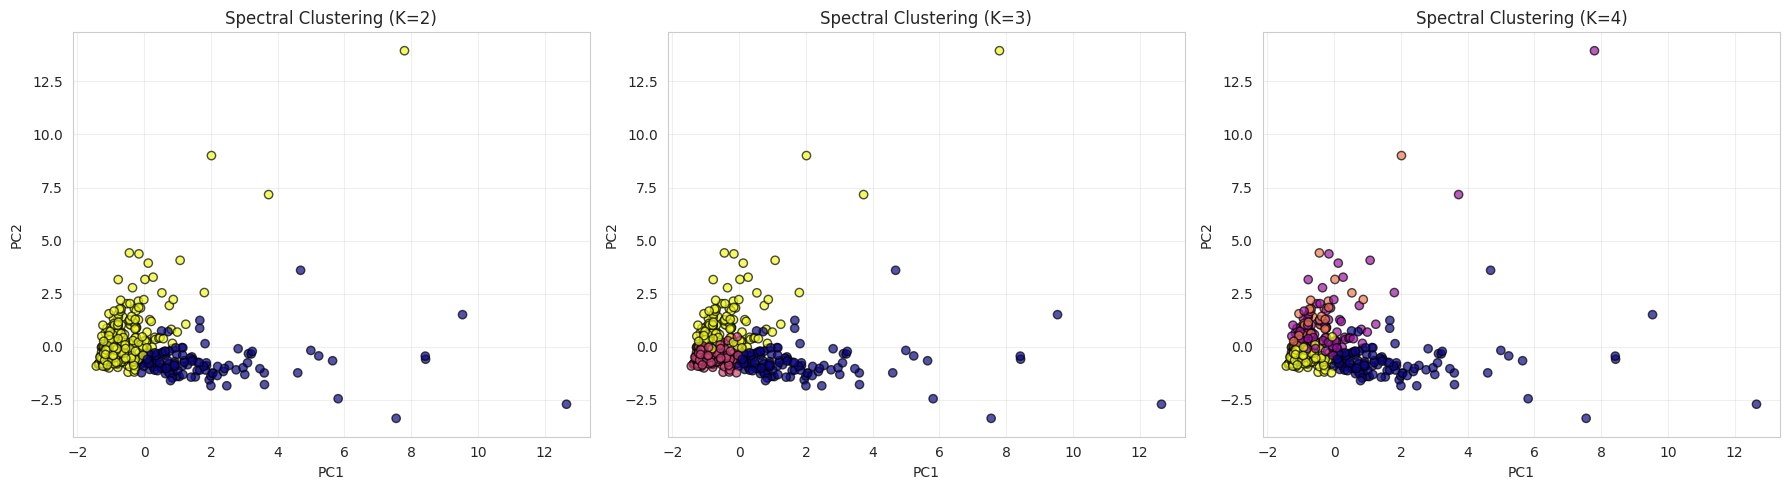

✅ Spectral Clustering visualizations created for K = 2, 3, 4.


In [42]:
#  Visualize Spectral Clustering results using PCA projection

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, k in enumerate([2, 3, 4]):
    labels = spectral_labels_dict[k]

    axes[idx].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='plasma', alpha=0.7, edgecolor='black')
    axes[idx].set_title(f'Spectral Clustering (K={k})')
    axes[idx].set_xlabel('PC1')
    axes[idx].set_ylabel('PC2')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Spectral Clustering visualizations created for K = 2, 3, 4.")

In [43]:
#  Apply Gaussian Mixture Model (GMM) for K = 2, 3, 4

gmm_results = {}
gmm_labels_dict = {}

for k in [2, 3, 4]:
    gmm = GaussianMixture(n_components=k, random_state=42)
    labels = gmm.fit_predict(X_scaled)

    gmm_results[k] = gmm
    gmm_labels_dict[k] = labels

    print(f"✅ GMM completed for K = {k}")

✅ GMM completed for K = 2
✅ GMM completed for K = 3
✅ GMM completed for K = 4


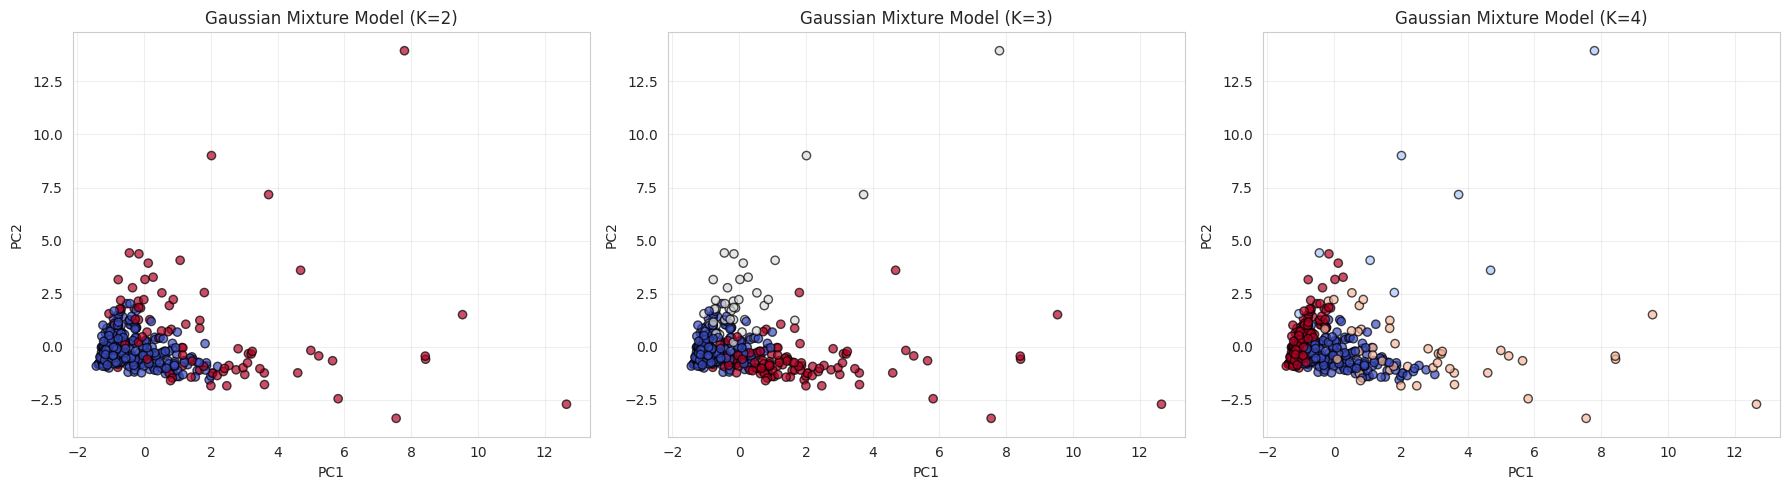

✅ GMM visualizations created for K = 2, 3, 4.


In [44]:
# Visualize GMM clustering results using PCA projection

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, k in enumerate([2, 3, 4]):
    labels = gmm_labels_dict[k]

    axes[idx].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='coolwarm', alpha=0.7, edgecolor='black')
    axes[idx].set_title(f'Gaussian Mixture Model (K={k})')
    axes[idx].set_xlabel('PC1')
    axes[idx].set_ylabel('PC2')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ GMM visualizations created for K = 2, 3, 4.")

In [45]:
#  Evaluate clustering performance using internal validation metrics

evaluation_results = []

def evaluate_model(model_name, k, labels, X_data):
    silhouette = silhouette_score(X_data, labels)
    dbi = davies_bouldin_score(X_data, labels)
    ch = calinski_harabasz_score(X_data, labels)
    dunn = dunn_index(X_data.values, labels)

    # Extra evaluation technique: Gap Statistic
    # Note: Gap Statistic is computed using K-Means style compactness idea
    gap = compute_gap_statistic(X_data, k)

    evaluation_results.append({
        'Algorithm': model_name,
        'K': k,
        'Silhouette Score': silhouette,
        'Davies-Bouldin Index': dbi,
        'Calinski-Harabasz Index': ch,
        'Dunn Index': dunn,
        'Gap Statistic': gap
    })

# Evaluate K-Means
for k in [2, 3, 4]:
    evaluate_model('K-Means', k, kmeans_labels_dict[k], X_scaled)

# Evaluate Spectral Clustering
for k in [2, 3, 4]:
    evaluate_model('Spectral Clustering', k, spectral_labels_dict[k], X_scaled)

# Evaluate GMM
for k in [2, 3, 4]:
    evaluate_model('Gaussian Mixture Model', k, gmm_labels_dict[k], X_scaled)

# Create results DataFrame
evaluation_df = pd.DataFrame(evaluation_results)

print("✅ Evaluation completed for all algorithms and all K values.")
evaluation_df

✅ Evaluation completed for all algorithms and all K values.


,Algorithm,K,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Dunn Index,Gap Statistic
0,K-Means,2,0.547215,1.131770,153.128086,0.015711,3.384614
1,K-Means,3,0.548287,0.927935,140.135183,0.028769,3.470932
2,K-Means,4,0.348471,1.147466,145.810111,0.023551,3.585728
3,Spectral Clustering,2,0.347806,1.261365,122.398552,0.021921,3.390693
4,Spectral Clustering,3,0.207650,1.348957,98.475227,0.011226,3.477504
5,Spectral Clustering,4,0.209502,1.368813,78.581327,0.008597,3.582470
6,Gaussian Mixture Model,2,0.449708,1.907724,84.414893,0.018758,3.374104
7,Gaussian Mixture Model,3,0.315904,1.471152,91.252433,0.015668,3.464773
8,Gaussian Mixture Model,4,0.163255,1.705931,74.030195,0.011552,3.574599


In [46]:
#  Format evaluation results for better readability

evaluation_df_rounded = evaluation_df.copy()

for col in ['Silhouette Score', 'Davies-Bouldin Index', 'Calinski-Harabasz Index', 'Dunn Index', 'Gap Statistic']:
    evaluation_df_rounded[col] = evaluation_df_rounded[col].round(4)

print("Formatted evaluation table:")
evaluation_df_rounded

Formatted evaluation table:


,Algorithm,K,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Dunn Index,Gap Statistic
0,K-Means,2,0.5472,1.1318,153.1281,0.0157,3.3846
1,K-Means,3,0.5483,0.9279,140.1352,0.0288,3.4709
2,K-Means,4,0.3485,1.1475,145.8101,0.0236,3.5857
3,Spectral Clustering,2,0.3478,1.2614,122.3986,0.0219,3.3907
4,Spectral Clustering,3,0.2077,1.3490,98.4752,0.0112,3.4775
5,Spectral Clustering,4,0.2095,1.3688,78.5813,0.0086,3.5825
6,Gaussian Mixture Model,2,0.4497,1.9077,84.4149,0.0188,3.3741
7,Gaussian Mixture Model,3,0.3159,1.4712,91.2524,0.0157,3.4648
8,Gaussian Mixture Model,4,0.1633,1.7059,74.0302,0.0116,3.5746


In [48]:
#  Identify best model according to each metric

print("BEST RESULTS BY METRIC")
print("=" * 60)

best_silhouette = evaluation_df_rounded.loc[evaluation_df_rounded['Silhouette Score'].idxmax()]
best_dbi = evaluation_df_rounded.loc[evaluation_df_rounded['Davies-Bouldin Index'].idxmin()]
best_ch = evaluation_df_rounded.loc[evaluation_df_rounded['Calinski-Harabasz Index'].idxmax()]
best_dunn = evaluation_df_rounded.loc[evaluation_df_rounded['Dunn Index'].idxmax()]
best_gap = evaluation_df_rounded.loc[evaluation_df_rounded['Gap Statistic'].idxmax()]

print("Best Silhouette Score:")
print(best_silhouette)
print()

print("Best Davies-Bouldin Index (lowest is best):")
print(best_dbi)
print()

print("Best Calinski-Harabasz Index:")
print(best_ch)
print()

print("Best Dunn Index:")
print(best_dunn)
print()

print("Best Gap Statistic:")
print(best_gap)

BEST RESULTS BY METRIC
Best Silhouette Score:
Algorithm                   K-Means
K                                 3
Silhouette Score             0.5483
Davies-Bouldin Index         0.9279
Calinski-Harabasz Index    140.1352
Dunn Index                   0.0288
Gap Statistic                3.4709
Name: 1, dtype: object

Best Davies-Bouldin Index (lowest is best):
Algorithm                   K-Means
K                                 3
Silhouette Score             0.5483
Davies-Bouldin Index         0.9279
Calinski-Harabasz Index    140.1352
Dunn Index                   0.0288
Gap Statistic                3.4709
Name: 1, dtype: object

Best Calinski-Harabasz Index:
Algorithm                   K-Means
K                                 2
Silhouette Score             0.5472
Davies-Bouldin Index         1.1318
Calinski-Harabasz Index    153.1281
Dunn Index                   0.0157
Gap Statistic                3.3846
Name: 0, dtype: object

Best Dunn Index:
Algorithm                   K-Means

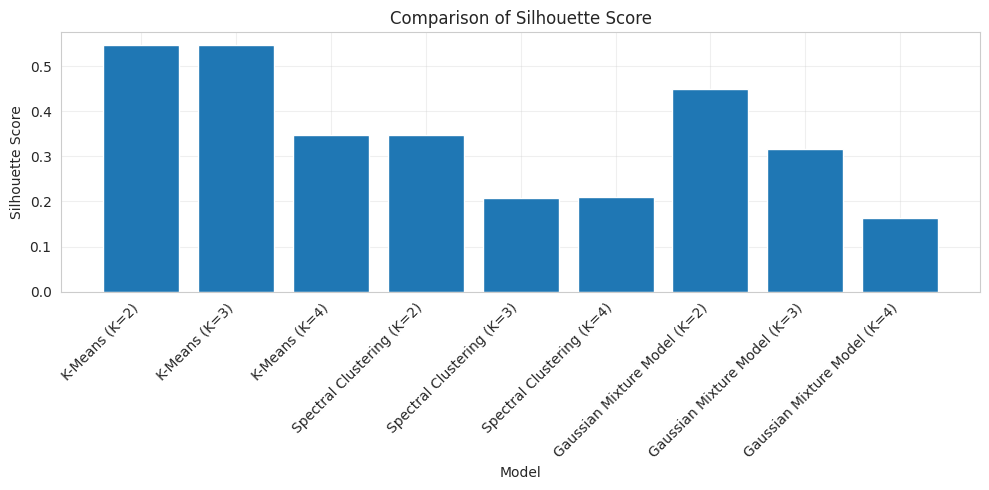

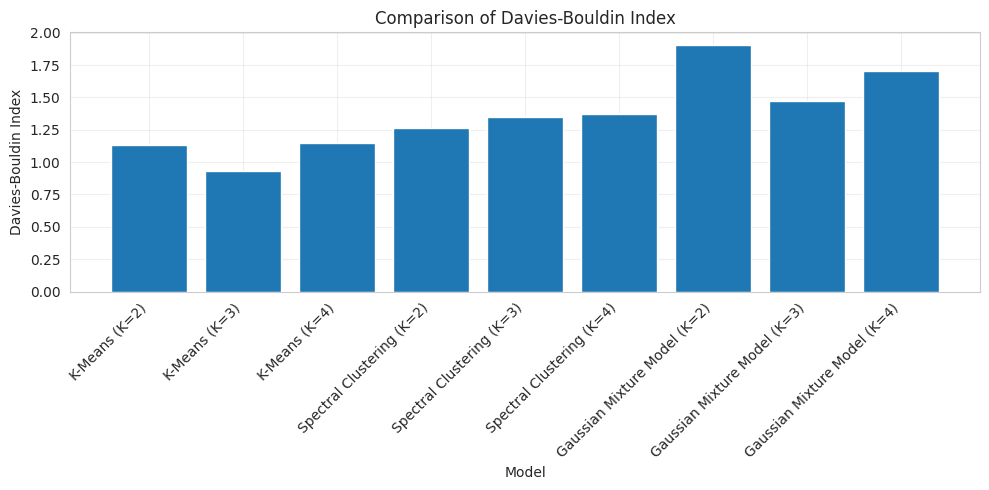

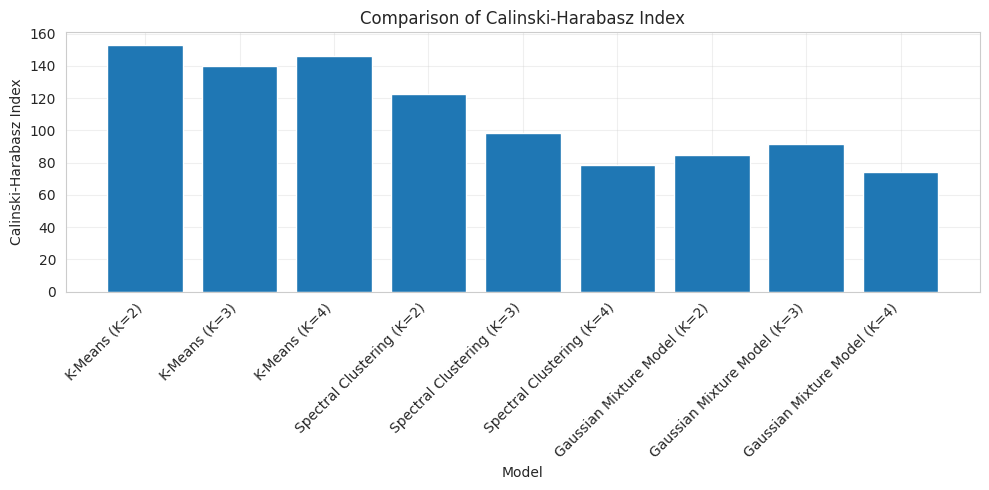

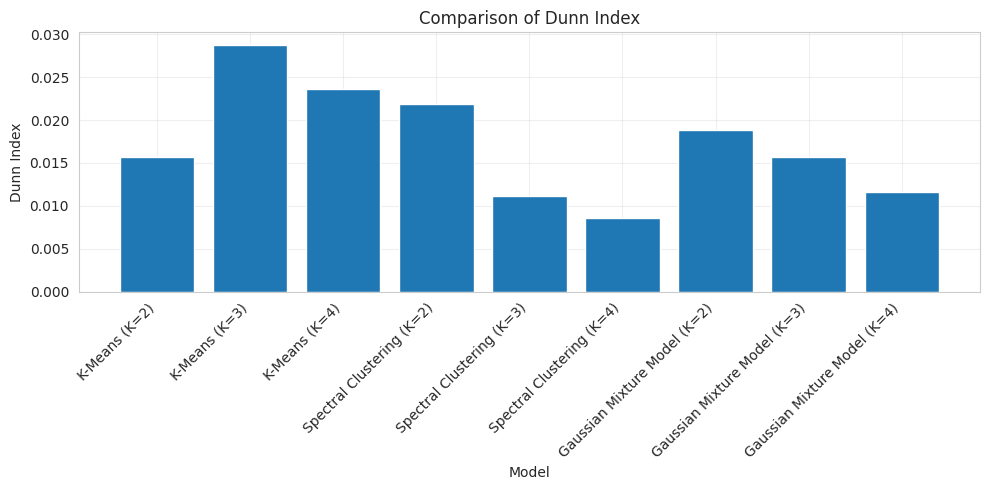

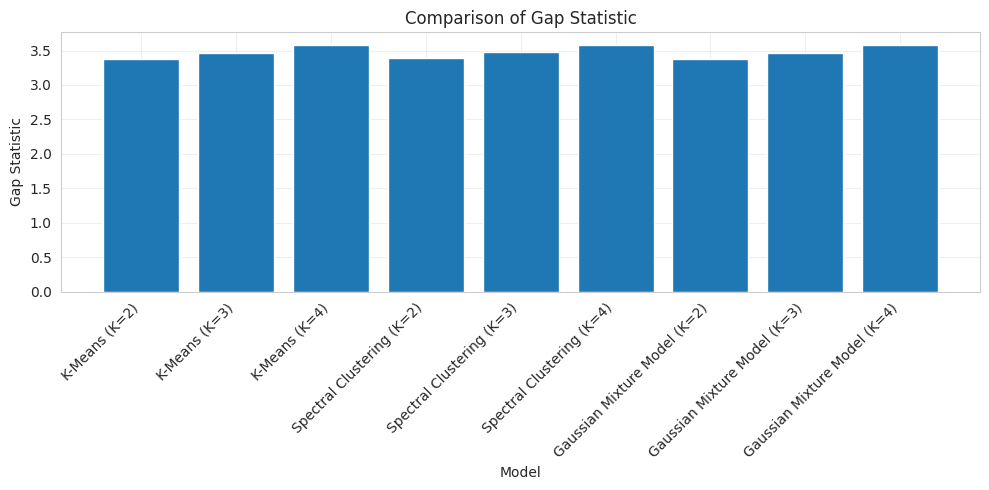

✅ Metric comparison charts created.


In [49]:
#  Visual comparison of evaluation metrics

metrics_to_plot = [
    'Silhouette Score',
    'Davies-Bouldin Index',
    'Calinski-Harabasz Index',
    'Dunn Index',
    'Gap Statistic'
]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 5))

    labels_for_plot = evaluation_df_rounded['Algorithm'] + ' (K=' + evaluation_df_rounded['K'].astype(str) + ')'
    plt.bar(labels_for_plot, evaluation_df_rounded[metric])

    plt.title(f'Comparison of {metric}')
    plt.xlabel('Model')
    plt.ylabel(metric)
    plt.xticks(rotation=45, ha='right')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print("✅ Metric comparison charts created.")

In [50]:
#  Define a function for cluster profiling using ORIGINAL data

def profile_clusters(X_original_data, labels, algorithm_name, k):
    profiled_df = X_original_data.copy()
    profiled_df['Cluster'] = labels

    cluster_profile = profiled_df.groupby('Cluster').mean()

    print(f"\n{'='*70}")
    print(f"Cluster Profile for {algorithm_name} with K = {k}")
    print(f"{'='*70}")
    print(cluster_profile.round(2))

    return cluster_profile

print("✅ Cluster profiling function defined.")

✅ Cluster profiling function defined.


In [51]:
#  Cluster profiling for K-Means

kmeans_profiles = {}

for k in [2, 3, 4]:
    profile = profile_clusters(X_original, kmeans_labels_dict[k], 'K-Means', k)
    kmeans_profiles[k] = profile


Cluster Profile for K-Means with K = 2
            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                     
0        12157.30   4028.17   5402.72  3066.07           1667.69     1256.89
1        10802.76  19282.33  27390.25  3116.67          12139.73     3568.84

Cluster Profile for K-Means with K = 3
            Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
Cluster                                                                      
0        10440.93  19386.42  28656.09   2190.24          13327.80     2374.20
1        12062.91   4115.10   5534.97   2940.68           1696.17     1299.11
2        34782.00  30367.00  16898.00  48701.50            755.50    26776.00

Cluster Profile for K-Means with K = 4
            Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
Cluster                                                                      
0         5591.44  10113.0

In [52]:
# Cluster profiling for Spectral Clustering

spectral_profiles = {}

for k in [2, 3, 4]:
    profile = profile_clusters(X_original, spectral_labels_dict[k], 'Spectral Clustering', k)
    spectral_profiles[k] = profile


Cluster Profile for Spectral Clustering with K = 2
            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                     
0         5920.05  12211.59  18058.59  1677.13           8104.67     1769.45
1        14332.97   3335.04   4073.63  3607.04            877.63     1431.04

Cluster Profile for Spectral Clustering with K = 3
            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                     
0         6149.92  12331.95  18259.50  1688.12           8192.67     1794.08
1         6556.24   2696.93   3447.86  1462.73            860.41      832.30
2        23529.47   4137.94   4865.27  6191.91            925.72     2147.01

Cluster Profile for Spectral Clustering with K = 4
            Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
Cluster                                                                  

In [53]:
#  Cluster profiling for Gaussian Mixture Model

gmm_profiles = {}

for k in [2, 3, 4]:
    profile = profile_clusters(X_original, gmm_labels_dict[k], 'Gaussian Mixture Model', k)
    gmm_profiles[k] = profile


Cluster Profile for Gaussian Mixture Model with K = 2
            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                     
0        10753.43   4006.22   5608.90  2281.51           1867.40     1005.25
1        17132.74  13164.58  17593.14  6325.52           7055.77     3663.76

Cluster Profile for Gaussian Mixture Model with K = 3
            Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
Cluster                                                                      
0        11395.41   2945.47   4019.20   2320.47           1105.56      993.58
1        29093.73   7171.69   6515.75  11037.62            727.46     3448.85
2         6366.38  12010.06  17900.92   1563.73           7998.31     1992.85

Cluster Profile for Gaussian Mixture Model with K = 4
            Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
Cluster                                                    

In [54]:
#  Dynamically determine the best model

best_overall = evaluation_df_rounded.sort_values(
    by=['Silhouette Score', 'Gap Statistic', 'Dunn Index'],
    ascending=[False, False, False]
).iloc[0]

best_algo = best_overall['Algorithm']
best_k = int(best_overall['K'])

print("✅ Best model automatically selected:")
print(f"Algorithm: {best_algo}")
print(f"K: {best_k}")

✅ Best model automatically selected:
Algorithm: K-Means
K: 3


In [55]:
# Retrieve the correct cluster profile dynamically

if best_algo == 'K-Means':
    best_profile = kmeans_profiles[best_k]
elif best_algo == 'Spectral Clustering':
    best_profile = spectral_profiles[best_k]
else:
    best_profile = gmm_profiles[best_k]

print("✅ Retrieved best cluster profile successfully.")

✅ Retrieved best cluster profile successfully.


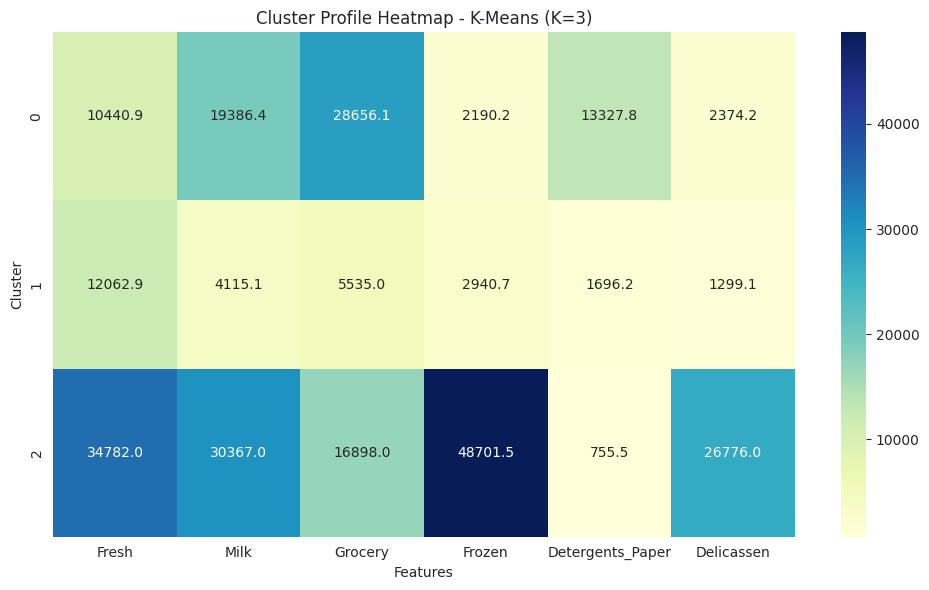

✅ Heatmap generated for best model.


In [56]:
#  Visualize cluster profile of BEST model

plt.figure(figsize=(10, 6))
sns.heatmap(best_profile, annot=True, fmt='.1f', cmap='YlGnBu')

plt.title(f'Cluster Profile Heatmap - {best_algo} (K={best_k})')
plt.xlabel('Features')
plt.ylabel('Cluster')

plt.tight_layout()
plt.show()

print("✅ Heatmap generated for best model.")

In [57]:
#  Show sorted evaluation results

sorted_results = evaluation_df_rounded.sort_values(
    by=['Silhouette Score', 'Gap Statistic', 'Dunn Index'],
    ascending=[False, False, False]
)

print("Evaluation results sorted:")
sorted_results

Evaluation results sorted:


,Algorithm,K,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Dunn Index,Gap Statistic
1,K-Means,3,0.5483,0.9279,140.1352,0.0288,3.4709
0,K-Means,2,0.5472,1.1318,153.1281,0.0157,3.3846
6,Gaussian Mixture Model,2,0.4497,1.9077,84.4149,0.0188,3.3741
2,K-Means,4,0.3485,1.1475,145.8101,0.0236,3.5857
3,Spectral Clustering,2,0.3478,1.2614,122.3986,0.0219,3.3907
7,Gaussian Mixture Model,3,0.3159,1.4712,91.2524,0.0157,3.4648
5,Spectral Clustering,4,0.2095,1.3688,78.5813,0.0086,3.5825
4,Spectral Clustering,3,0.2077,1.3490,98.4752,0.0112,3.4775
8,Gaussian Mixture Model,4,0.1633,1.7059,74.0302,0.0116,3.5746


In [59]:
#  Final model conclusion

print("\nFINAL MODEL SELECTION")
print("=" * 60)

print(f"Recommended Algorithm: {best_algo}")
print(f"Recommended Number of Clusters (K): {best_k}")

print("\nReasoning:")
print("- This model achieved the strongest performance across multiple evaluation metrics.")
print("- It has high cluster separation (Silhouette Score).")
print("- It shows meaningful structure compared to random data (Gap Statistic).")
print("- It maintains good compactness and separation (Dunn Index).")

print("\nConclusion:")
print("This model is selected as the final clustering solution for customer segmentation.")


FINAL MODEL SELECTION
Recommended Algorithm: K-Means
Recommended Number of Clusters (K): 3

Reasoning:
- This model achieved the strongest performance across multiple evaluation metrics.
- It has high cluster separation (Silhouette Score).
- It shows meaningful structure compared to random data (Gap Statistic).
- It maintains good compactness and separation (Dunn Index).

Conclusion:
This model is selected as the final clustering solution for customer segmentation.
